# LightShift-PatchCore — Notebook 04 · B1 (banque mémoire photométriquement augmentée)

**CPU · MVTec AD · `bottle`, `carpet`, `metal_nut` · MLflow**

**Objectif :** tester l'effet de B1 en construisant une **nouvelle banque de patchs normaux** issue d'images sources avec et sans changements d'éclairage. Nous la comparons à la banque **Vanilla** du notebook 01, à **taille de coreset identique** et sur les **mêmes images test** que le notebook 02.

- Ne modifie **jamais** les données MVTec originales.
- Ne touche **pas** aux banques Vanilla : B1 est sauvegardée séparément.
- Le backbone ResNet-18 reste **gelé** : B1 n'implique pas de rétropropagation.
- Les seuils de chaque méthode sont calibrés sur `source_val`, jamais sur `target_test`.
- Les choix d'hyperparamètres doivent être fixés avant de regarder les résultats du test. Les métriques du notebook 04 sont une évaluation pilote, pas une sélection automatique de configuration.

**Note scientifique :** nous fixons le même *budget de candidats* et le même *nombre final de patchs* que Vanilla ; la banque B1 ne peut donc pas gagner simplement en étant plus grande. Nous utilisons deux vues de chaque image source (propre + photométrique) avec moitié moins de patchs par vue.

## Étape 1 — Bibliothèques, chemins et CPU

In [1]:
from pathlib import Path
import os, sys, json, random, time, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm import tqdm
from torchvision.models import resnet18, ResNet18_Weights
from torchvision import transforms
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score
from scipy.ndimage import gaussian_filter
from skimage.measure import label, regionprops
import yaml

WORKSPACE = Path('/workspace') if Path('/workspace/notebooks').is_dir() else Path.cwd().resolve().parent
NOTEBOOKS_DIR = WORKSPACE/'notebooks' if (WORKSPACE/'notebooks').is_dir() else Path.cwd()
BASELINE_DIR = NOTEBOOKS_DIR/'artifacts_baseline'
LIGHTING_DIR = NOTEBOOKS_DIR/'artifacts_lighting'
CONFIG_FILE = NOTEBOOKS_DIR/'configs'/'baseline_cpu.yaml'
MODELS_DIR = WORKSPACE/'models' if (WORKSPACE/'models').is_dir() else NOTEBOOKS_DIR/'models'
OUT = NOTEBOOKS_DIR/'artifacts_b1'
for sub in ('config','metrics','figures','banks'):(OUT/sub).mkdir(parents=True,exist_ok=True)
assert CONFIG_FILE.is_file(), f'Configuration notebook 01 introuvable : {CONFIG_FILE}'
CFG = yaml.safe_load(CONFIG_FILE.read_text(encoding='utf-8'))
assert CFG['backbone']=='resnet18' and CFG['layers']==['layer2','layer3']
CATEGORIES=list(CFG['categories']);IMAGE_SIZE=int(CFG['image_size']);SEED=int(CFG['seed'])
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
DEVICE=torch.device('cpu');torch.set_num_threads(max(1,min(4,os.cpu_count() or 1)))
print('Catégories:',CATEGORIES,'| résolution:',IMAGE_SIZE,'| PyTorch:',torch.__version__,'| CPU')

Catégories: ['bottle', 'carpet', 'metal_nut'] | résolution: 224 | PyTorch: 2.15.0+cu132 | CPU


## Étape 2 — Recharger les splits d’origine et les banques Vanilla (sans reconstruire Vanilla)

In [2]:
def locate_mvtec_root(base, categories):
    base=Path(base)
    candidates=[base,base.parent,WORKSPACE/'data']
    for d in list(candidates):
        if d.is_dir(): candidates += [p for p in d.glob('*') if p.is_dir()] + [p for p in d.glob('*/*') if p.is_dir()]
    for d in dict.fromkeys(candidates):
        if all((d/c/'train'/'good').is_dir() for c in categories):return d
    raise FileNotFoundError('MVTec AD introuvable. Vérifie CFG[data_root].')

MVTEC_ROOT=locate_mvtec_root(CFG['data_root'],CATEGORIES)
SPLITS={};VANILLA_BANKS={}
for cat in CATEGORIES:
    split_file=BASELINE_DIR/'splits'/f'{cat}_splits.json'
    bank_file=MODELS_DIR/f'{cat}_resnet18_cpu_bank.npy'
    assert split_file.is_file() and bank_file.is_file(),f'Fichiers notebook 01 manquants : {cat}'
    payload=json.loads(split_file.read_text(encoding='utf-8'))
    SPLITS[cat]={name:[MVTEC_ROOT/path for path in paths] for name,paths in payload.items()}
    assert set(SPLITS[cat])=={'source_train','source_val','target_calibration','target_test'}
    allpaths=[str(p.resolve()) for group in SPLITS[cat].values() for p in group]
    assert len(allpaths)==len(set(allpaths)), f'Fuite : {cat}'
    assert all(p.is_file() for group in SPLITS[cat].values() for p in group)
    VANILLA_BANKS[cat]=np.load(bank_file,allow_pickle=False).astype(np.float32)
print('Dataset:',MVTEC_ROOT)
display(pd.DataFrame([dict(category=c,**{k:len(v) for k,v in SPLITS[c].items()},vanilla_bank_size=len(VANILLA_BANKS[c])) for c in CATEGORIES]))

Dataset: /workspace/data/mvtec


,category,source_train,source_val,target_calibration,target_test,vanilla_bank_size
0,bottle,146,31,32,83,256
1,carpet,196,42,42,117,256
2,metal_nut,154,33,33,115,256


## Étape 3 — Recharger exactement ResNet-18, les transformations et les masques

In [3]:
weights = ResNet18_Weights.DEFAULT
mean, std = weights.transforms().mean, weights.transforms().std
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])
mask_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.PILToTensor()
])

class FeatureExtractor(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = resnet18(weights=weights).to(DEVICE).eval()
        self.features = {}
        self.hooks = []
        for layer_name in CFG['layers']:
            hook = getattr(self.backbone, layer_name).register_forward_hook(
                lambda module, inputs, output, key=layer_name: self.features.__setitem__(key, output)
            )
            self.hooks.append(hook)
        for p in self.backbone.parameters(): p.requires_grad_(False)

    @torch.inference_mode()
    def forward(self, batch):
        self.features.clear()
        self.backbone(batch.to(DEVICE))
        h = self.features['layer2']
        parts = [h]
        for name in CFG['layers']:
            if name != 'layer2':
                parts.append(F.interpolate(self.features[name], size=h.shape[-2:], mode='bilinear', align_corners=False))
        return torch.cat(parts, dim=1)
extractor = FeatureExtractor()

def feature_to_patches(x):
    return x.squeeze(0).permute(1,2,0).reshape(-1,x.shape[1]).cpu().numpy().astype(np.float32)

@torch.inference_mode()
def fmap_from_rgb(rgb):
    return extractor(image_transform(rgb.convert('RGB')).unsqueeze(0))

def load_mask(path,category):
    if path.parent.name=='good':return np.zeros((IMAGE_SIZE,IMAGE_SIZE),dtype=np.uint8)
    mask_path=MVTEC_ROOT/category/'ground_truth'/path.parent.name/(path.stem+'_mask.png')
    if not mask_path.is_file():raise FileNotFoundError(mask_path)
    with Image.open(mask_path) as im:
        return (mask_transform(im.convert('L')).squeeze(0).numpy()>0).astype(np.uint8)

for cat in CATEGORIES:
    with Image.open(SPLITS[cat]['source_val'][0]) as im: sample=fmap_from_rgb(im)
    assert sample.shape[1]==VANILLA_BANKS[cat].shape[1],cat
print('Feature dimension:',sample.shape[1],'| Grille:',tuple(sample.shape[-2:]))

Feature dimension: 384 | Grille: (28, 28)


## Étape 4 — Perturbations identiques au notebook 02

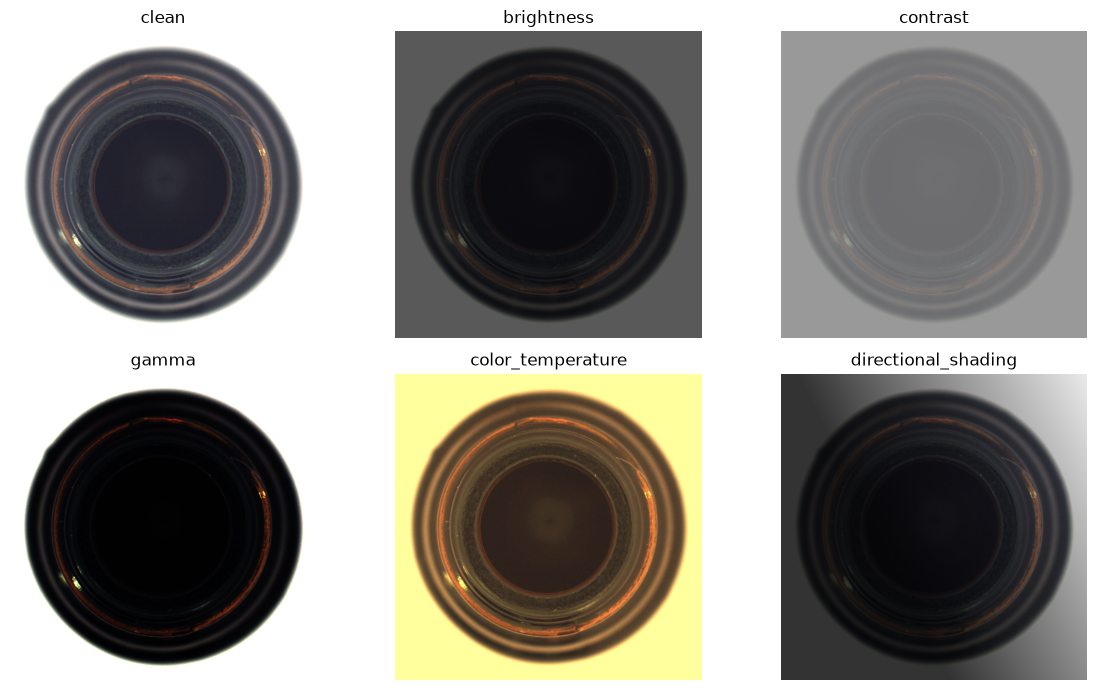

In [4]:
def apply_lighting_shift(rgb_image, kind='clean', severity=0, image_key=''):
    x = np.asarray(rgb_image.convert('RGB'), dtype=np.float32) / 255.0
    if kind == 'clean' or severity == 0: return rgb_image.convert('RGB').copy()
    assert severity in (1, 3, 5), 'Sévérité attendue : 1, 3 ou 5.'
    t = severity / 5.0
    if kind == 'brightness':
        # Assombrissement progressif
        x = x * (1.0 - 0.65 * t)
    elif kind == 'contrast':
        # Contraste réduit autour de 0.5
        x = (x - 0.5) * (1.0 - 0.80 * t) + 0.5
    elif kind == 'gamma':
        x = np.power(x, 1.0 + 1.8 * t)
    elif kind == 'color_temperature':
        gains = np.array([1 + 0.38*t, 1 + 0.04*t, 1 - 0.38*t],dtype=np.float32)
        x = x * gains[None, None, :]
    elif kind == 'directional_shading':
        key = hashlib.sha256(f'{SEED}|{image_key}'.encode()).digest()
        angle = int.from_bytes(key[:4], 'big') / 2**32 * 2 * np.pi
        h,w = x.shape[:2]
        xx = np.linspace(-1, 1, w, dtype=np.float32)[None,:]
        yy = np.linspace(-1, 1, h, dtype=np.float32)[:,None]
        gradient = (xx * np.cos(angle) + yy * np.sin(angle)) / np.sqrt(2)
        factor = np.clip(1.0 - 0.65*t + 0.60*t*gradient, 0.20, 1.15)
        x = x * factor[...,None]
    else: raise ValueError(f'Perturbation inconnue : {kind}')
    return Image.fromarray(np.uint8(np.round(np.clip(x,0,1)*255)), mode='RGB')
SHIFTS=['brightness','contrast','gamma','color_temperature','directional_shading']
with Image.open(SPLITS[CATEGORIES[0]]['source_train'][0]) as im:
    fig,axes=plt.subplots(2,3,figsize=(12,7))
    for ax,kind in zip(axes.flat,['clean']+SHIFTS):
        ax.imshow(apply_lighting_shift(im,kind,5,'B1_demo'))
        ax.set_title(kind);ax.axis('off')
    plt.tight_layout();plt.show()

## Étape 5 — Paramètres B1 et protocole

**Comparaison équitable :** même sélection des images sources, même limite de candidats, même coreset final, mêmes réglages kNN, même split de validation/test. Deux vues par image (une propre, une augmentée). Pour limiter le CPU, 32 patchs par vue au lieu de 64 patchs sur une seule vue. **Le choix du nombre de vues est un paramètre expérimental : ne l'ajuste pas en observant le test.**

Pour une première exécution, activer `FAST_MODE=True` (4 conditions par catégorie). Ensuite, `False` pour 16 conditions sans modifier les paramètres B1.

In [5]:
B1_CFG={
    'seed':SEED,
    'views_per_image':2,
    'n_train_images':CFG['max_train_images_cpu'],
    'patches_per_image_total':int(CFG['patches_per_image']),
    'candidate_cap':int(CFG['coreset_candidate_cap']),
    'coreset_projection_dim':int(CFG['coreset_projection_dim']),
    'coreset_size':int(CFG['coreset_size']),
    'augmentation_kinds':SHIFTS,
    'augmentation_severities':[1,3,5],
    'source_threshold_alpha':0.05,
}
assert B1_CFG['views_per_image']==2 and B1_CFG['patches_per_image_total']%2==0
FAST_MODE=True
PIXEL_METRICS=False  # True = calcul pixel AUROC + AU-PRO (plus lent)
LOG_TO_MLFLOW=True
CONDITIONS=[('clean',0),('brightness',5),('contrast',5),('directional_shading',5)] if FAST_MODE else [('clean',0)]+[(k,s) for k in SHIFTS for s in (1,3,5)]
protocol={**B1_CFG,'fast_mode':FAST_MODE,'pixel_metrics':PIXEL_METRICS,'conditions':CONDITIONS,'baseline_config':str(CONFIG_FILE),'note':'B1 train source only; thresholds source_val only; evaluate target_test'}
(OUT/'config'/'b1_protocol.yaml').write_text(yaml.safe_dump(protocol,sort_keys=False,allow_unicode=True),encoding='utf-8')
print('Conditions:',len(CONDITIONS),'| candidats par image:',B1_CFG['patches_per_image_total'],'| coreset:',B1_CFG['coreset_size'])

Conditions: 4 | candidats par image: 64 | coreset: 256


## Étape 6 — Sélection déterministe des images et des augmentations B1

In [6]:
def selected_train_paths(category):
    paths=list(SPLITS[category]['source_train'])
    max_images=B1_CFG['n_train_images']
    if max_images is not None and len(paths)>max_images:
        rng=np.random.default_rng(SEED)
        paths=[paths[i] for i in sorted(rng.choice(len(paths),size=max_images,replace=False))]
    return paths

def augmentation_plan(category):
    paths=selected_train_paths(category)
    choices=[(kind,severity) for kind in SHIFTS for severity in (1,3,5)]
    # Le plan est construit exclusivement depuis source_train, avant toute mesure test.
    # L'ordre des 15 conditions est mélangé à graine fixe.
    rng=np.random.default_rng(SEED)
    order=rng.permutation(len(choices))
    plan=[{'path':p,'kind':choices[order[i%len(order)]][0],'severity':choices[order[i%len(order)]][1]} for i,p in enumerate(paths)]
    return plan

for cat in CATEGORIES:
    plan=augmentation_plan(cat)
    assert all(entry['path'] in SPLITS[cat]['source_train'] for entry in plan)
    assert len(plan)==len(selected_train_paths(cat))
    (OUT/'config'/f'{cat}_b1_augmentation_plan.json').write_text(json.dumps([{'source':str(item['path'].relative_to(MVTEC_ROOT)),'kind':item['kind'],'severity':item['severity']} for item in plan],indent=2),encoding='utf-8')
    print(cat,'images sources:',len(plan),'exemples:',[(x['kind'],x['severity']) for x in plan[:4]])

bottle images sources: 80 exemples: [('gamma', 1), ('gamma', 3), ('color_temperature', 1), ('contrast', 1)]
carpet images sources: 80 exemples: [('gamma', 1), ('gamma', 3), ('color_temperature', 1), ('contrast', 1)]
metal_nut images sources: 80 exemples: [('gamma', 1), ('gamma', 3), ('color_temperature', 1), ('contrast', 1)]


## Étape 7 — Construire les banques candidates B1 (clean + image augmentée)

In [7]:
def build_b1_candidates(category):
    rng=np.random.default_rng(SEED)  # même graine de sélection de patches que Vanilla
    n_per_view=B1_CFG['patches_per_image_total']//2
    pieces=[]; plan=augmentation_plan(category)
    for item in tqdm(plan,desc=f'Features B1 {category}'):
        p=item['path']
        with Image.open(p) as im:
            clean=im.convert('RGB')
            shifted=apply_lighting_shift(clean,item['kind'],item['severity'],str(p.relative_to(MVTEC_ROOT)))
        for rgb in (clean,shifted):
            patches=feature_to_patches(fmap_from_rgb(rgb))
            ix=rng.choice(len(patches),size=min(n_per_view,len(patches)),replace=False)
            pieces.append(patches[ix])
    candidates=np.concatenate(pieces,axis=0).astype(np.float32)
    assert np.isfinite(candidates).all()
    return candidates,len(plan)

print('Générateur B1 prêt. Aucune image de test dans la banque.')

Générateur B1 prêt. Aucune image de test dans la banque.


## Étape 8 — Coreset glouton approximatif (identique à la baseline) et construction des nouvelles banques

In [8]:
def approximate_greedy_coreset(bank, size=256, candidate_cap=3000, proj_dim=64, seed=42):
    rng = np.random.default_rng(seed)
    bank = np.asarray(bank, dtype=np.float32)
    if len(bank) > candidate_cap:
        ids = rng.choice(len(bank), candidate_cap, replace=False)
        bank = bank[ids]
    n, dim = bank.shape
    size = min(size, n)
    projection = rng.standard_normal((dim, proj_dim)).astype(np.float32) / np.sqrt(proj_dim)
    z = bank @ projection
    selected=[]
    min_sq = np.full(n, np.inf, dtype=np.float32)
    idx=int(rng.integers(n))
    for _ in tqdm(range(size), desc='Coreset', leave=False):
        selected.append(idx)
        min_sq=np.minimum(min_sq, np.sum((z-z[idx])**2, axis=1))
        min_sq[selected] = -1.0
        idx=int(np.argmax(min_sq))
    return bank[selected]
B1_BANKS={}; BANK_RECORDS=[]
for cat in CATEGORIES:
    tic=time.perf_counter()
    candidates,n_images=build_b1_candidates(cat)
    assert len(candidates)==n_images*B1_CFG['patches_per_image_total']
    bank=approximate_greedy_coreset(candidates,
        size=len(VANILLA_BANKS[cat]),
        candidate_cap=B1_CFG['candidate_cap'],
        proj_dim=B1_CFG['coreset_projection_dim'],seed=SEED)
    assert bank.shape==VANILLA_BANKS[cat].shape, f'Budget différent de Vanilla : {cat}'
    B1_BANKS[cat]=bank
    np.save(OUT/'banks'/f'{cat}_resnet18_cpu_b1_bank.npy',bank)
    BANK_RECORDS.append({'category':cat,'train_images':n_images,'candidate_patches':len(candidates),
                        'coreset_patches':len(bank),'bank_MB':round(bank.nbytes/1024**2,3),
                        'build_seconds':round(time.perf_counter()-tic,2)})
    del candidates
BANK_DF=pd.DataFrame(BANK_RECORDS)
BANK_DF.to_csv(OUT/'metrics'/'b1_bank_build.csv',index=False)
display(BANK_DF)
print('Les fichiers Vanilla dans models/ n’ont pas été modifiés.')

Features B1 metal_nut: 100%|██████████| 80/80 [00:13<00:00,  5.84it/s]
                                                            

,category,train_images,candidate_patches,coreset_patches,bank_MB,build_seconds
0,bottle,80,5120,256,0.375,16.25
1,carpet,80,5120,256,0.375,18.20
2,metal_nut,80,5120,256,0.375,13.90


Les fichiers Vanilla dans models/ n’ont pas été modifiés.


## Étape 9 — Scoring kNN Vanilla et B1 avec le même backbone

In [9]:
KNN_V={c:NearestNeighbors(n_neighbors=1,algorithm='brute',metric='euclidean',n_jobs=1).fit(VANILLA_BANKS[c]) for c in CATEGORIES}
KNN_B1={c:NearestNeighbors(n_neighbors=1,algorithm='brute',metric='euclidean',n_jobs=1).fit(B1_BANKS[c]) for c in CATEGORIES}

def score_fmap(fmap,knn,need_map=False):
    h,w=map(int,fmap.shape[-2:])
    d,_=knn.kneighbors(feature_to_patches(fmap),return_distance=True)
    patchmap=d[:,0].reshape(h,w)
    score=float(patchmap.max())
    if not need_map:return score,None
    up=F.interpolate(torch.from_numpy(patchmap.astype(np.float32))[None,None],size=(IMAGE_SIZE,IMAGE_SIZE),mode='bilinear',align_corners=False)[0,0].numpy()
    return score,gaussian_filter(up,float(CFG['pixel_smoothing_sigma'])).astype(np.float32)

@torch.inference_mode()
def predict_two(path,category,kind='clean',severity=0,need_map=False):
    with Image.open(path) as im:
        rgb=apply_lighting_shift(im,kind,severity,str(path.relative_to(MVTEC_ROOT)))
    fmap=fmap_from_rgb(rgb)
    return score_fmap(fmap,KNN_V[category],need_map),score_fmap(fmap,KNN_B1[category],need_map)

for cat in CATEGORIES:
    (v,_),(b,_)=predict_two(SPLITS[cat]['source_val'][0],cat)
    print(cat,'Vanilla:',round(v,4),'B1:',round(b,4))

bottle Vanilla: 3.7266 B1: 3.4608
carpet Vanilla: 3.1696 B1: 3.1776
metal_nut Vanilla: 4.9114 B1: 4.9248


## Étape 10 — Fixer les seuils sur `source_val` (sans utiliser le test)

- Vanilla : réutilise **exactement** le seuil source enregistré dans le notebook 02.
- B1 : calcule un **nouveau seuil source** sur les mêmes images `source_val` (la nouvelle banque a une échelle de scores différente).
- Aucun seuil n'est ajusté à partir des images `target_test`.

In [10]:
SOURCE_FILE=LIGHTING_DIR/'config'/'source_thresholds.json'
assert SOURCE_FILE.is_file(),f'Fichier notebook 02 absent : {SOURCE_FILE}'
source_payload=json.loads(SOURCE_FILE.read_text(encoding='utf-8'))
assert abs(float(source_payload['alpha'])-B1_CFG['source_threshold_alpha'])<1e-12
THRESHOLDS={}
for cat in CATEGORIES:
    paths=SPLITS[cat]['source_val']
    b1_scores=[]
    for p in tqdm(paths,desc=f'Validation B1 {cat}'):
        (_, _),(b, _)=predict_two(p,cat)
        b1_scores.append(b)
    assert len(b1_scores)>=2 and np.isfinite(b1_scores).all()
    THRESHOLDS[cat]={'Vanilla':float(source_payload['thresholds'][cat]),
                     'B1':float(np.quantile(b1_scores,1-B1_CFG['source_threshold_alpha']))}
(OUT/'config'/'source_thresholds_b1.json').write_text(json.dumps(THRESHOLDS,indent=2),encoding='utf-8')
display(pd.DataFrame([{'category':c,**THRESHOLDS[c]} for c in CATEGORIES]))

Validation B1 metal_nut: 100%|██████████| 33/33 [00:03<00:00,  9.96it/s]


,category,Vanilla,B1
0,bottle,4.585290,4.795637
1,carpet,3.590598,3.690853
2,metal_nut,5.414710,5.683508


## Étape 11 — Tester les métriques image (AUROC, AP, précision, rappel, F1, FPR)

In [11]:
RESULTS=[]
RESULT_FILE=OUT/'metrics'/'b1_vs_vanilla.csv'
for cat in CATEGORIES:
    test_paths=SPLITS[cat]['target_test']
    y=np.asarray([int(p.parent.name!='good') for p in test_paths],dtype=np.uint8)
    assert set(y)=={0,1},f'Classes manquantes sur {cat}'
    for kind,sev in CONDITIONS:
        tic=time.perf_counter();scores={'Vanilla':[],'B1':[]}
        for p in tqdm(test_paths,desc=f'Test {cat} {kind} s{sev}',leave=False):
            (v,_),(b,_)=predict_two(p,cat,kind,sev)
            scores['Vanilla'].append(v);scores['B1'].append(b)
        for method,vals in scores.items():
            vals=np.asarray(vals,dtype=np.float64)
            preds=(vals>THRESHOLDS[cat][method]).astype(np.uint8)
            result={'category':cat,'shift':kind,'severity':sev,'method':method,'n_test':len(y),
                    'image_AUROC':float(roc_auc_score(y,vals)),
                    'image_AP':float(average_precision_score(y,vals)),
                    'precision':float(precision_score(y,preds,zero_division=0)),
                    'recall':float(recall_score(y,preds,zero_division=0)),
                    'F1':float(f1_score(y,preds,zero_division=0)),
                    'FPR':float(preds[y==0].mean()),
                    'threshold':float(THRESHOLDS[cat][method]),
                    'mean_normal_score':float(vals[y==0].mean()),
                    'mean_anomaly_score':float(vals[y==1].mean()),
                    'eval_seconds_condition':round(time.perf_counter()-tic,2)}
            RESULTS.append(result)
        pd.DataFrame(RESULTS).to_csv(RESULT_FILE,index=False)
RESULTS_DF=pd.DataFrame(RESULTS)
display(RESULTS_DF.head(12))
print('Résultats sauvegardés:',RESULT_FILE)

,category,shift,severity,method,n_test,image_AUROC,image_AP,precision,recall,F1,FPR,threshold,mean_normal_score,mean_anomaly_score,eval_seconds_condition
0,bottle,clean,0,Vanilla,83,0.976190,0.991321,0.968254,0.968254,0.968254,0.100000,4.585290,3.891865,6.035213,10.48
1,bottle,clean,0,B1,83,0.992857,0.997816,0.983607,0.952381,0.967742,0.050000,4.795637,3.979299,6.007707,10.50
2,bottle,brightness,5,Vanilla,83,0.967460,0.991263,0.759036,1.000000,0.863014,1.000000,4.585290,4.758030,5.597656,10.71
3,bottle,brightness,5,B1,83,0.993651,0.998002,1.000000,0.873016,0.932203,0.000000,4.795637,3.786847,5.521540,10.72
4,bottle,contrast,5,Vanilla,83,0.973810,0.992387,1.000000,0.825397,0.904348,0.000000,4.585290,3.992600,5.148259,10.92
5,bottle,contrast,5,B1,83,0.984921,0.995370,1.000000,0.714286,0.833333,0.000000,4.795637,3.679835,5.137756,10.94
6,bottle,directional_shading,5,Vanilla,83,0.696032,0.877604,0.787500,1.000000,0.881119,0.850000,4.585290,5.324532,5.791191,14.45
7,bottle,directional_shading,5,B1,83,0.903968,0.971141,0.855072,0.936508,0.893939,0.500000,4.795637,4.758170,5.578064,14.47
8,carpet,clean,0,Vanilla,117,0.908106,0.970751,0.985915,0.786517,0.875000,0.035714,3.590598,3.289121,4.332804,18.99
9,carpet,clean,0,B1,117,0.890449,0.963041,0.958333,0.775281,0.857143,0.107143,3.690853,3.400964,4.334992,19.02


Résultats sauvegardés: /workspace/notebooks/artifacts_b1/metrics/b1_vs_vanilla.csv


## Étape 12 — Métriques pixel (optionnelles, coûteuses en RAM/CPU)

Les métriques pixel comparent les heatmaps aux masques de défaut. La fonction ci-dessous utilise une grille de seuils, comme le notebook 02 ; son AU-PRO est une **approximation** dépendante de la grille de seuils. La valeur est à comparer à un protocole de référence seulement si les définitions sont identiques.

In [12]:
def compute_aupro(gt_masks,pred_maps,fpr_limit=0.30,thresholds_count=80):
    gt=np.asarray(gt_masks,dtype=bool); scores=np.asarray(pred_maps,dtype=np.float32)
    neg=(~gt).sum()
    if neg==0:return float('nan')
    components=[]
    for i in range(len(gt)):
        for reg in regionprops(label(gt[i],connectivity=2)):
            yyxx=reg.coords; components.append((i,yyxx[:,0],yyxx[:,1]))
    if not components:return float('nan')
    thresholds=np.linspace(float(scores.max())+1e-6,float(scores.min())-1e-6,thresholds_count)
    fprs=[0.0];pro=[0.0]
    for th in thresholds:
        pred=scores>=th
        fprs.append(float((pred&(~gt)).sum()/neg))
        pro.append(float(np.mean([pred[i,ys,xs].mean() for i,ys,xs in components])))
        if fprs[-1]>=fpr_limit:break
    x=np.asarray(fprs);y=np.asarray(pro);order=np.argsort(x);x=x[order];y=y[order]
    ux=np.unique(x);uy=np.array([y[x==u].max() for u in ux])
    if ux[-1]<fpr_limit:
        ux=np.r_[ux,fpr_limit];uy=np.r_[uy,uy[-1]]
    grid=np.unique(np.r_[0.0,fpr_limit,ux[(ux>0)&(ux<fpr_limit)]])
    return float(np.trapezoid(np.interp(grid,ux,uy),grid)/fpr_limit)

if PIXEL_METRICS:
    pixel_rows=[]
    for cat in CATEGORIES:
        paths=SPLITS[cat]['target_test']
        masks=np.stack([load_mask(p,cat) for p in paths])
        for kind,sev in CONDITIONS:
            maps={'Vanilla':[],'B1':[]}
            for p in tqdm(paths,desc=f'Pixel {cat} {kind} s{sev}',leave=False):
                (v,vm),(b,bm)=predict_two(p,cat,kind,sev,need_map=True)
                maps['Vanilla'].append(vm);maps['B1'].append(bm)
            for method,ms in maps.items():
                ms=np.stack(ms)
                pixel_rows.append(dict(category=cat,shift=kind,severity=sev,method=method,
                    pixel_AUROC=float(roc_auc_score(masks.ravel(),ms.ravel())),
                    pixel_AUPRO=compute_aupro(masks,ms)))
    PIXEL_DF=pd.DataFrame(pixel_rows)
    RESULTS_DF=RESULTS_DF.merge(PIXEL_DF,on=['category','shift','severity','method'],how='left')
    RESULTS_DF.to_csv(RESULT_FILE,index=False)
    display(PIXEL_DF.head(12))
else: print('PIXEL_METRICS=False : métriques pixel non calculées, volontairement.')

PIXEL_METRICS=False : métriques pixel non calculées, volontairement.


## Étape 13 — Comparer les gains B1 − Vanilla et enregistrer les figures

,category,shift,severity,delta_image_AUROC_B1_minus_Vanilla,delta_F1_B1_minus_Vanilla,delta_FPR_B1_minus_Vanilla
0,bottle,brightness,5,0.026190,0.069190,-1.000000
1,bottle,clean,0,0.016667,-0.000512,-0.050000
2,bottle,contrast,5,0.011111,-0.071014,0.000000
3,bottle,directional_shading,5,0.207937,0.012821,-0.350000
4,carpet,brightness,5,-0.066613,-0.063307,0.107143
5,carpet,clean,0,-0.017657,-0.017857,0.071429
6,carpet,contrast,5,-0.027287,0.000000,0.000000
7,carpet,directional_shading,5,0.129615,-0.001330,0.107143
8,metal_nut,brightness,5,0.230205,-0.165703,-0.045455
9,metal_nut,clean,0,0.022483,-0.193885,-0.090909


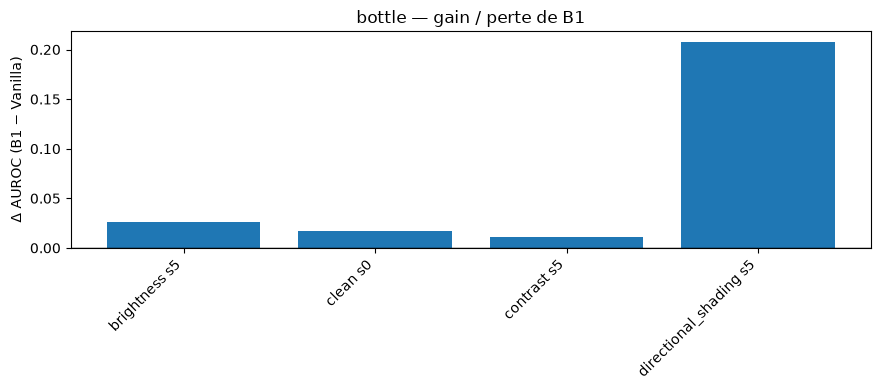

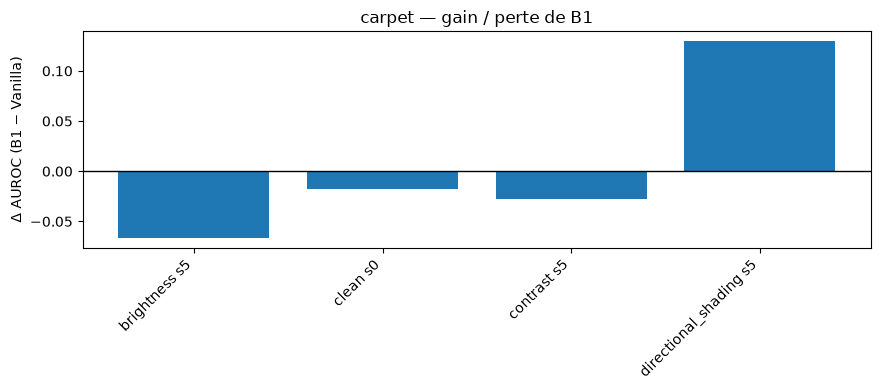

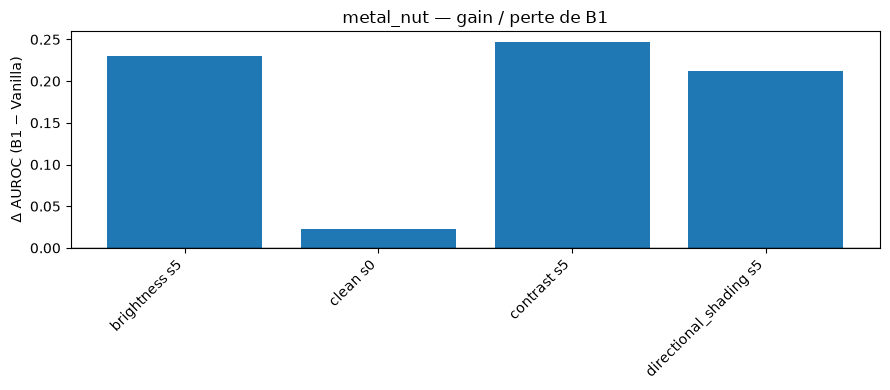

Figure(s) et tableau des gains sauvegardés. Ne pas optimiser B1 sur target_test.


In [13]:
pivot=RESULTS_DF.pivot(index=['category','shift','severity'],columns='method',values=['image_AUROC','F1','FPR'])
GAIN=pd.DataFrame(index=pivot.index)
for metric in ['image_AUROC','F1','FPR']:
    GAIN[f'delta_{metric}_B1_minus_Vanilla']=pivot[(metric,'B1')]-pivot[(metric,'Vanilla')]
GAIN=GAIN.reset_index()
GAIN.to_csv(OUT/'metrics'/'b1_gains.csv',index=False)
display(GAIN)
for cat in CATEGORIES:
    sub=GAIN[GAIN.category==cat]
    labels_=[f'{row.shift if False else row["shift"]} s{row["severity"]}' for _,row in sub.iterrows()]
    fig,ax=plt.subplots(figsize=(max(9,len(sub)*0.8),4))
    ax.bar(np.arange(len(sub)),sub['delta_image_AUROC_B1_minus_Vanilla'])
    ax.axhline(0,color='black',linewidth=1)
    ax.set_xticks(np.arange(len(sub)),labels_,rotation=45,ha='right')
    ax.set_ylabel('Δ AUROC (B1 − Vanilla)');ax.set_title(f'{cat} — gain / perte de B1')
    fig.tight_layout();fig.savefig(OUT/'figures'/f'{cat}_b1_delta_auroc.png',dpi=140)
    plt.show()
print('Figure(s) et tableau des gains sauvegardés. Ne pas optimiser B1 sur target_test.')

## Étape 14 — Visualiser Vanilla vs B1 sur le même défaut

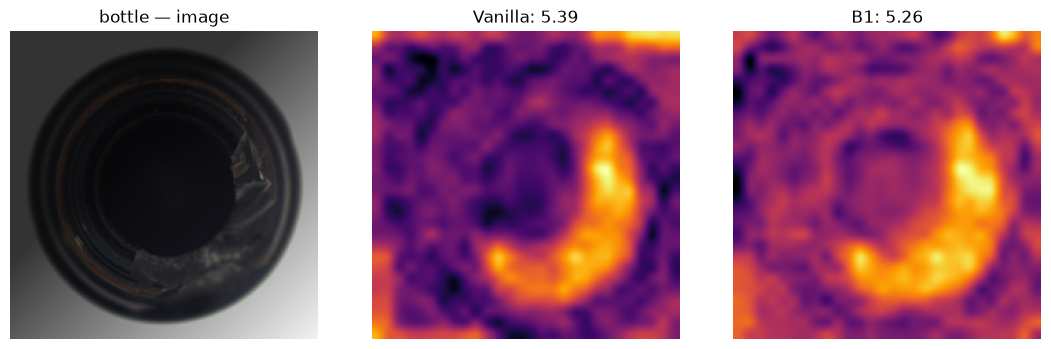

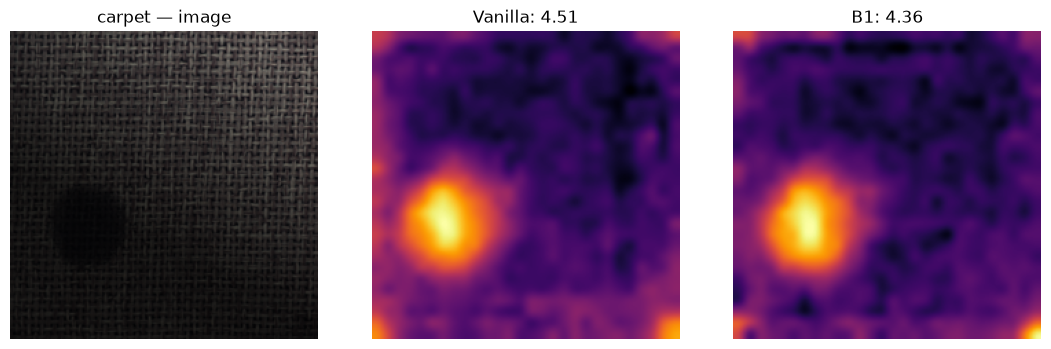

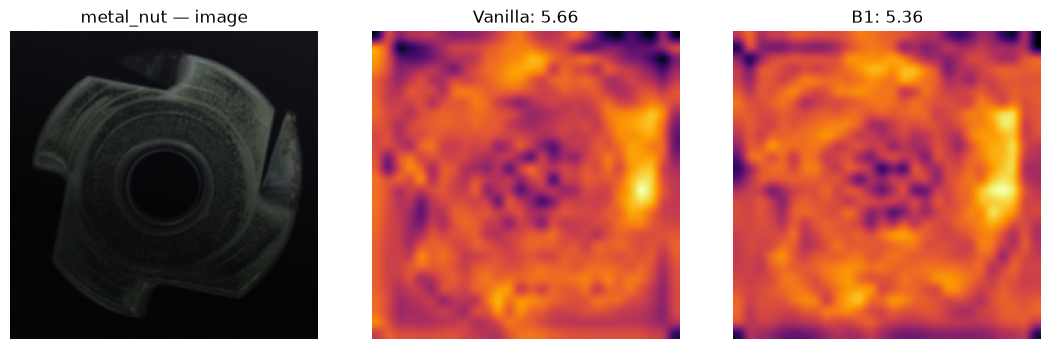

In [14]:
for cat in CATEGORIES:
    p=next(p for p in SPLITS[cat]['target_test'] if p.parent.name!='good')
    (v,vm),(b,bm)=predict_two(p,cat,'directional_shading',5,need_map=True)
    with Image.open(p) as im: rgb=apply_lighting_shift(im,'directional_shading',5,str(p.relative_to(MVTEC_ROOT)))
    fig,ax=plt.subplots(1,3,figsize=(11,3.5))
    ax[0].imshow(rgb.resize((IMAGE_SIZE,IMAGE_SIZE)));ax[0].set_title(f'{cat} — image')
    ax[1].imshow(vm,cmap='inferno');ax[1].set_title(f'Vanilla: {v:.2f}')
    ax[2].imshow(bm,cmap='inferno');ax[2].set_title(f'B1: {b:.2f}')
    for a in ax:a.axis('off')
    fig.tight_layout();fig.savefig(OUT/'figures'/f'{cat}_b1_heatmap_example.png',dpi=140);plt.show()

## Étape 15 — Logger les expériences dans MLflow (une condition × méthode = un run)

In [15]:
if LOG_TO_MLFLOW:
    import mlflow
    MLFLOW_URI=os.getenv('MLFLOW_TRACKING_URI') or (OUT/'mlruns').resolve().as_uri()
    mlflow.set_tracking_uri(MLFLOW_URI)
    mlflow.set_experiment('LightShift-PatchCore-B1-CPU')
    for _,r in tqdm(RESULTS_DF.iterrows(),total=len(RESULTS_DF),desc='Logging MLflow'):
        with mlflow.start_run(run_name=f'{r["category"]}_{r["shift"]}_s{int(r["severity"])}_{r["method"]}'):
            mlflow.set_tags({'method':r['method'],'category':r['category'],'phase':'B1','dataset':'MVTec AD','hardware':'cpu'})
            mlflow.log_params({'backbone':CFG['backbone'],'image_size':IMAGE_SIZE,'seed':SEED,
                'category':r['category'],'shift':r['shift'],'severity':int(r['severity']),
                'method':r['method'],'coreset_size':int(len(B1_BANKS[r['category']])),
                'views_per_image':2,'candidate_cap':B1_CFG['candidate_cap'],
                'patches_per_image_total':B1_CFG['patches_per_image_total']})
            for metric in ['image_AUROC','image_AP','precision','recall','F1','FPR','threshold','mean_normal_score','mean_anomaly_score','pixel_AUROC','pixel_AUPRO']:
                if metric in r.index and pd.notna(r[metric]) and np.isfinite(float(r[metric])):
                    mlflow.log_metric(metric,float(r[metric]))
            mlflow.log_artifact(str(OUT/'config'/'b1_protocol.yaml'),artifact_path='config')
            mlflow.log_artifact(str(RESULT_FILE),artifact_path='reports')
            if r['method']=='B1':
                mlflow.log_artifact(str(OUT/'banks'/f'{r["category"]}_resnet18_cpu_b1_bank.npy'),artifact_path='banks')
    print('MLflow:',MLFLOW_URI,'| expérience LightShift-PatchCore-B1-CPU')
else: print('MLflow désactivé. Fichiers CSV et banques sauvegardés localement.')

2026/11/12 16:01:34 INFO mlflow.tracking.fluent: Experiment with name 'LightShift-PatchCore-B1-CPU' does not exist. Creating a new experiment.
Logging MLflow:   4%|▍         | 1/24 [00:00<00:10,  2.13it/s]

🏃 View run bottle_clean_s0_Vanilla at: http://mlflow:5000/#/experiments/5/runs/a5e22092dfd2403ba67d0811d3a9ba20
🧪 View experiment at: http://mlflow:5000/#/experiments/5


Logging MLflow:   8%|▊         | 2/24 [00:00<00:08,  2.48it/s]

🏃 View run bottle_clean_s0_B1 at: http://mlflow:5000/#/experiments/5/runs/62d99cf350af4d1fb3258c9ca6b9dea4
🧪 View experiment at: http://mlflow:5000/#/experiments/5


Logging MLflow:  12%|█▎        | 3/24 [00:01<00:07,  2.68it/s]

🏃 View run bottle_brightness_s5_Vanilla at: http://mlflow:5000/#/experiments/5/runs/e9f017ced72348509d843008a6e12f93
🧪 View experiment at: http://mlflow:5000/#/experiments/5


... (38 outputs left out)

Logging MLflow:  96%|█████████▌| 23/24 [00:08<00:00,  2.92it/s]

🏃 View run metal_nut_directional_shading_s5_Vanilla at: http://mlflow:5000/#/experiments/5/runs/c117c084ebfe4e74bf16342eb6877128
🧪 View experiment at: http://mlflow:5000/#/experiments/5


Logging MLflow: 100%|██████████| 24/24 [00:08<00:00,  2.73it/s]

🏃 View run metal_nut_directional_shading_s5_B1 at: http://mlflow:5000/#/experiments/5/runs/1739da8a3df54ea79570b53f06e98271
🧪 View experiment at: http://mlflow:5000/#/experiments/5
MLflow: http://mlflow:5000 | expérience LightShift-PatchCore-B1-CPU


## Étape 16 — Contrôles et conclusion

**Contrôles obligatoires** : tailles de banque identiques, images originales intactes, seuils définis sur `source_val`, fichiers sauvegardés et comparaison B1/Vanilla sur les mêmes images.

**Interprétation :** un gain d'AUROC indique que B1 améliore le ranking pour la condition considérée ; un gain de F1 accompagné d'une hausse du FPR peut être un compromis. Toujours lire AUROC, FPR et rappel ensemble.

**Suite du projet :** Notebook 05 = **B4**, entraînement d'un adaptateur résiduel 1×1 sur les features gelées, avec losses et checkpoints MLflow. Notebook 06 = ablations complètes B1, B2, B3, B4 et combinaisons.

In [16]:
assert len(RESULTS_DF)==len(CATEGORIES)*len(CONDITIONS)*2
for cat in CATEGORIES:
    assert B1_BANKS[cat].shape==VANILLA_BANKS[cat].shape
    assert all(p.is_file() for p in SPLITS[cat]['source_train']+SPLITS[cat]['target_test'])
    assert (OUT/'banks'/f'{cat}_resnet18_cpu_b1_bank.npy').is_file()
assert RESULT_FILE.is_file()
summary={'notebook':'04_B1_CPU','categories':CATEGORIES,'conditions':CONDITIONS,
         'config':protocol,'results_count':len(RESULTS_DF),'bank_sizes':{c:len(B1_BANKS[c]) for c in CATEGORIES},
         'next':'05_B4_adapter_cpu'}
(OUT/'config'/'summary.json').write_text(json.dumps(summary,indent=2,default=str),encoding='utf-8')
print('✅ B1 terminé pour',len(CATEGORIES),'catégories ;',len(CONDITIONS),'conditions ;',len(RESULTS_DF),'résultats')
print('✅ Fichiers dans',OUT)
print('➡️ Suite : notebook 05, B4 (adaptateur appris).')

✅ B1 terminé pour 3 catégories ; 4 conditions ; 24 résultats
✅ Fichiers dans /workspace/notebooks/artifacts_b1
➡️ Suite : notebook 05, B4 (adaptateur appris).
